## Problem 15: Forecasting U.S. Corporate Credit Spreads Using Macroeconomic and Financial Risk Indicators

In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [135]:
series = [
    "AAA",
    "BAA",
    "FEDFUNDS",
    "GS2",
    "GS10",
    "UNRATE",
    "INDPRO",
    "CPIAUCSL",
    "VIXCLS"
]

df = pd.DataFrame()

for series_id in series:

    url = (
        f"https://fred.stlouisfed.org/"
        f"graph/fredgraph.csv?id={series_id}"
    )

    temp = pd.read_csv(url)

    temp = temp.rename(
        columns={
            temp.columns[0]: "DATE"
        }
    )

    temp["DATE"] = pd.to_datetime(
        temp["DATE"]
    )

    temp = temp.set_index(
        "DATE"
    )

    if df.empty:
        df = temp

    else:

        df = df.join(
            temp,
            how="outer"
        )

In [136]:
for column in series:

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

In [137]:
df = df.resample("MS").mean()

df.head()

,AAA,BAA,FEDFUNDS,GS2,GS10,UNRATE,INDPRO,CPIAUCSL,VIXCLS
DATE,,,,,,,,,
1919-01-01,5.35,7.12,NaN,NaN,NaN,NaN,4.8739,NaN,NaN
1919-02-01,5.35,7.20,NaN,NaN,NaN,NaN,4.6585,NaN,NaN
1919-03-01,5.39,7.15,NaN,NaN,NaN,NaN,4.5238,NaN,NaN
1919-04-01,5.44,7.23,NaN,NaN,NaN,NaN,4.6046,NaN,NaN
1919-05-01,5.39,7.09,NaN,NaN,NaN,NaN,4.6315,NaN,NaN


In [138]:
df = df.loc[
    "1990-01-01":"2026-07-01"
].copy()

df.head()

,AAA,BAA,FEDFUNDS,GS2,GS10,UNRATE,INDPRO,CPIAUCSL,VIXCLS
DATE,,,,,,,,,
1990-01-01,8.99,9.94,8.23,8.09,8.21,5.4,61.7290,127.5,23.347273
1990-02-01,9.22,10.14,8.24,8.37,8.47,5.3,62.2896,128.0,23.262632
1990-03-01,9.37,10.21,8.28,8.63,8.59,5.2,62.5999,128.6,20.062273
1990-04-01,9.46,10.30,8.26,8.72,8.79,5.4,62.4359,128.9,21.403500
1990-05-01,9.47,10.41,8.18,8.64,8.76,5.4,62.6258,129.1,18.097727


In [139]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 439 entries, 1990-01-01 to 2026-07-01
Freq: MS
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   AAA       439 non-null    float64
 1   BAA       439 non-null    float64
 2   FEDFUNDS  439 non-null    float64
 3   GS2       439 non-null    float64
 4   GS10      439 non-null    float64
 5   UNRATE    438 non-null    float64
 6   INDPRO    439 non-null    float64
 7   CPIAUCSL  438 non-null    float64
 8   VIXCLS    439 non-null    float64
dtypes: float64(9)
memory usage: 34.3 KB


In [140]:
df.isna().sum()

AAA         0
BAA         0
FEDFUNDS    0
GS2         0
GS10        0
UNRATE      1
INDPRO      0
CPIAUCSL    1
VIXCLS      0
dtype: int64

In [141]:
df.describe().round(2)

,AAA,BAA,FEDFUNDS,GS2,GS10,UNRATE,INDPRO,CPIAUCSL,VIXCLS
count,439.00,439.00,439.00,439.00,439.00,438.00,439.00,438.00,439.00
mean,5.60,6.53,2.89,3.25,4.25,5.65,90.52,211.93,19.45
std,1.74,1.72,2.33,2.25,1.92,1.74,12.87,53.32,7.37
min,2.14,3.16,0.05,0.12,0.62,3.40,60.33,127.50,10.13
25%,4.08,5.19,0.34,0.96,2.64,4.30,86.23,164.72,14.15
50%,5.41,6.29,2.96,3.47,4.18,5.30,95.27,212.33,17.68
75%,7.02,7.94,5.22,4.97,5.70,6.57,100.39,244.12,22.92
max,9.56,10.74,8.29,8.72,8.89,14.80,104.10,333.98,62.67


In [142]:
df = df.rename(columns={
    "AAA": "aaa_yield",
    "BAA": "baa_yield",
    "FEDFUNDS": "fed_funds",
    "GS2": "treasury_2y",
    "GS10": "treasury_10y",
    "UNRATE": "unemployment",
    "INDPRO": "industrial_production",
    "CPIAUCSL": "cpi",
    "VIXCLS": "vix"
})

df.head()

,aaa_yield,baa_yield,fed_funds,treasury_2y,treasury_10y,unemployment,industrial_production,cpi,vix
DATE,,,,,,,,,
1990-01-01,8.99,9.94,8.23,8.09,8.21,5.4,61.7290,127.5,23.347273
1990-02-01,9.22,10.14,8.24,8.37,8.47,5.3,62.2896,128.0,23.262632
1990-03-01,9.37,10.21,8.28,8.63,8.59,5.2,62.5999,128.6,20.062273
1990-04-01,9.46,10.30,8.26,8.72,8.79,5.4,62.4359,128.9,21.403500
1990-05-01,9.47,10.41,8.18,8.64,8.76,5.4,62.6258,129.1,18.097727


In [143]:
df["default_spread"] = (
    df["baa_yield"]
    -
    df["aaa_yield"]
)

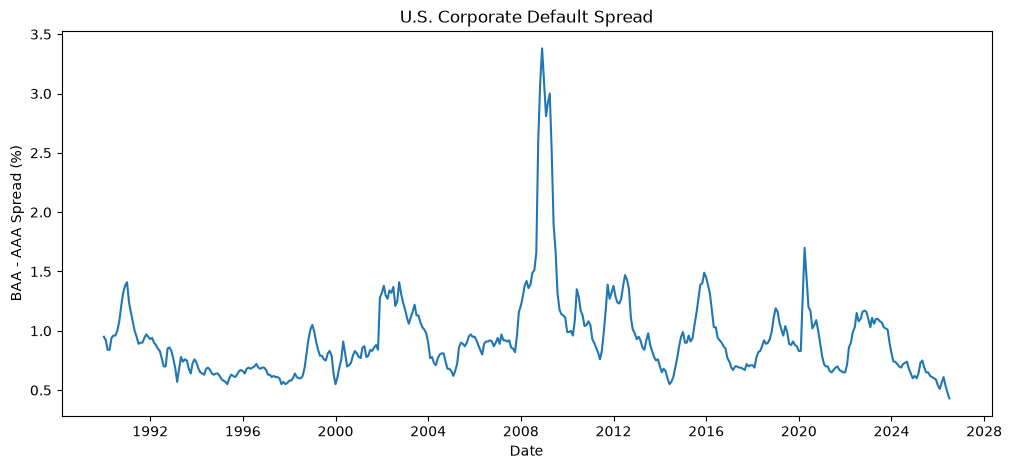

In [144]:
plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df["default_spread"]
)

plt.xlabel("Date")

plt.ylabel(
    "BAA - AAA Spread (%)"
)

plt.title(
    "U.S. Corporate Default Spread"
)

plt.show()

In [145]:
df["spread_change_3m"] = (
    df["default_spread"]
    -
    df["default_spread"].shift(3)
)

In [146]:
df["spread_change_12m"] = (
    df["default_spread"]
    -
    df["default_spread"].shift(12)
)

In [147]:
df["future_spread_change"] = (
    df["default_spread"].shift(-6)
    -
    df["default_spread"]
)

In [148]:
df["term_spread"] = (
    df["treasury_10y"]
    -
    df["treasury_2y"]
)

In [149]:
df["ip_growth"] = (
    100
    * (
        np.log(
            df["industrial_production"]
        )
        -
        np.log(
            df["industrial_production"].shift(12)
        )
    )
)

In [150]:
df["inflation"] = (
    100
    * (
        np.log(
            df["cpi"]
        )
        -
        np.log(
            df["cpi"].shift(12)
        )
    )
)

In [151]:
features = [
    "default_spread",
    "spread_change_3m",
    "spread_change_12m",
    "aaa_yield",
    "baa_yield",
    "fed_funds",
    "treasury_2y",
    "treasury_10y",
    "term_spread",
    "unemployment",
    "ip_growth",
    "inflation",
    "vix"
]

In [152]:
print(
    "Number of candidate predictors:",
    len(features)
)

Number of candidate predictors: 13


In [153]:
model_df = df[
    features
    + ["future_spread_change"]
].copy()

model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

model_df = model_df.dropna()

model_df.head()

,default_spread,spread_change_3m,spread_change_12m,aaa_yield,baa_yield,fed_funds,treasury_2y,treasury_10y,term_spread,unemployment,ip_growth,inflation,vix,future_spread_change
DATE,,,,,,,,,,,,,,
1991-01-01,1.41,0.20,0.46,9.04,10.45,6.91,7.13,8.09,0.96,6.4,-0.966112,5.493372,27.429091,-0.52
1991-02-01,1.24,-0.08,0.32,8.83,10.07,6.25,6.87,7.85,0.98,6.6,-2.611770,5.176193,21.598421,-0.34
1991-03-01,1.16,-0.22,0.32,8.93,10.09,6.12,7.10,8.11,1.01,6.8,-3.685794,4.708539,17.744211,-0.26
1991-04-01,1.08,-0.33,0.24,8.86,9.94,5.91,6.95,8.04,1.09,6.7,-3.159955,4.697834,17.372727,-0.14
1991-05-01,1.00,-0.24,0.06,8.86,9.86,5.78,6.78,8.07,1.29,6.9,-2.526630,4.912208,16.932273,-0.03


In [154]:
model_df.shape

(420, 14)

In [155]:
model_df.describe().round(3)

,default_spread,spread_change_3m,spread_change_12m,aaa_yield,baa_yield,fed_funds,treasury_2y,treasury_10y,term_spread,unemployment,ip_growth,inflation,vix,future_spread_change
count,420.000,420.000,420.000,420.000,420.000,420.000,420.000,420.000,420.000,420.000,420.000,420.000,420.000,420.000
mean,0.936,-0.005,-0.011,5.498,6.434,2.729,3.101,4.128,1.027,5.676,1.380,2.578,19.353,-0.009
std,0.370,0.229,0.458,1.657,1.634,2.200,2.139,1.822,0.919,1.765,4.276,1.494,7.465,0.340
min,0.540,-1.320,-2.270,2.140,3.160,0.050,0.120,0.620,-0.930,3.400,-19.017,-1.978,10.125,-1.860
25%,0.697,-0.083,-0.223,4.060,5.140,0.200,0.930,2.568,0.250,4.300,-0.323,1.701,14.015,-0.130
50%,0.870,-0.020,-0.030,5.350,6.285,2.405,3.075,4.125,0.955,5.300,2.258,2.555,17.543,-0.020
75%,1.050,0.060,0.180,6.930,7.890,5.072,4.880,5.540,1.800,6.625,3.700,3.108,22.585,0.080
max,3.380,1.720,2.220,9.040,10.450,6.910,7.590,8.280,2.830,14.800,15.317,8.599,62.669,1.990


**Plot: Forecast Target**

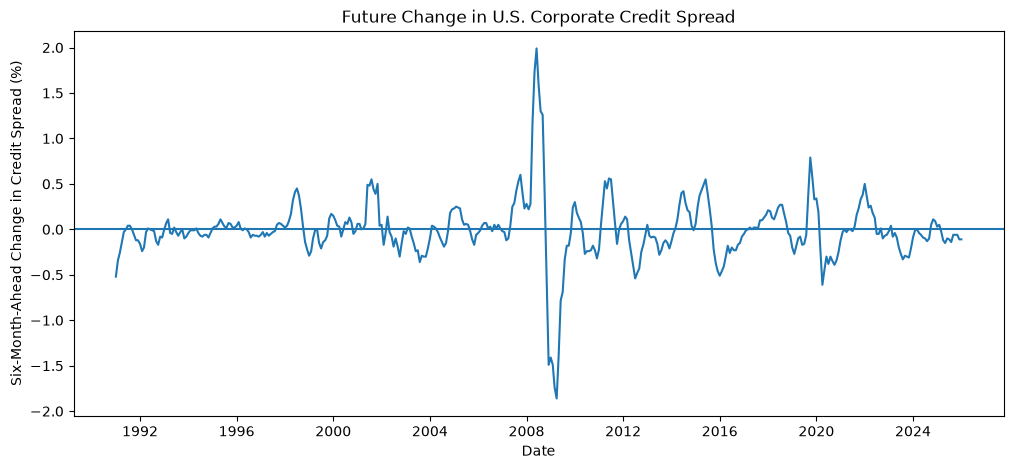

In [156]:
plt.figure(figsize=(12, 5))

plt.plot(
    model_df.index,
    model_df["future_spread_change"]
)

plt.axhline(
    y=0
)

plt.xlabel("Date")

plt.ylabel(
    "Six-Month-Ahead Change in Credit Spread (%)"
)

plt.title(
    "Future Change in U.S. Corporate Credit Spread"
)

plt.show()

Positive values indicate future widening.

Negative values indicate future narrowing.

In [157]:
correlation_matrix = (
    model_df[features]
    .corr()
)

correlation_matrix.round(2)

,default_spread,spread_change_3m,spread_change_12m,aaa_yield,baa_yield,fed_funds,treasury_2y,treasury_10y,term_spread,unemployment,ip_growth,inflation,vix
default_spread,1.00,0.31,0.62,-0.17,0.05,-0.37,-0.36,-0.29,0.27,0.36,-0.66,-0.24,0.63
spread_change_3m,0.31,1.00,0.42,-0.01,0.06,0.01,0.00,-0.04,-0.08,-0.10,0.03,0.14,0.35
spread_change_12m,0.62,0.42,1.00,0.02,0.16,0.04,0.04,-0.04,-0.18,-0.13,-0.38,-0.07,0.45
aaa_yield,-0.17,-0.01,0.02,1.00,0.97,0.71,0.82,0.97,0.02,-0.02,0.25,0.12,0.00
baa_yield,0.05,0.06,0.16,0.97,1.00,0.64,0.75,0.92,0.08,0.06,0.10,0.07,0.14
fed_funds,-0.37,0.01,0.04,0.71,0.64,1.00,0.96,0.80,-0.64,-0.48,0.30,0.28,-0.13
treasury_2y,-0.36,0.00,0.04,0.82,0.75,0.96,1.00,0.90,-0.53,-0.41,0.32,0.31,-0.15
treasury_10y,-0.29,-0.04,-0.04,0.97,0.92,0.80,0.90,1.00,-0.12,-0.12,0.32,0.21,-0.13
term_spread,0.27,-0.08,-0.18,0.02,0.08,-0.64,-0.53,-0.12,1.00,0.72,-0.12,-0.32,0.11
unemployment,0.36,-0.10,-0.13,-0.02,0.06,-0.48,-0.41,-0.12,0.72,1.00,-0.25,-0.34,0.19


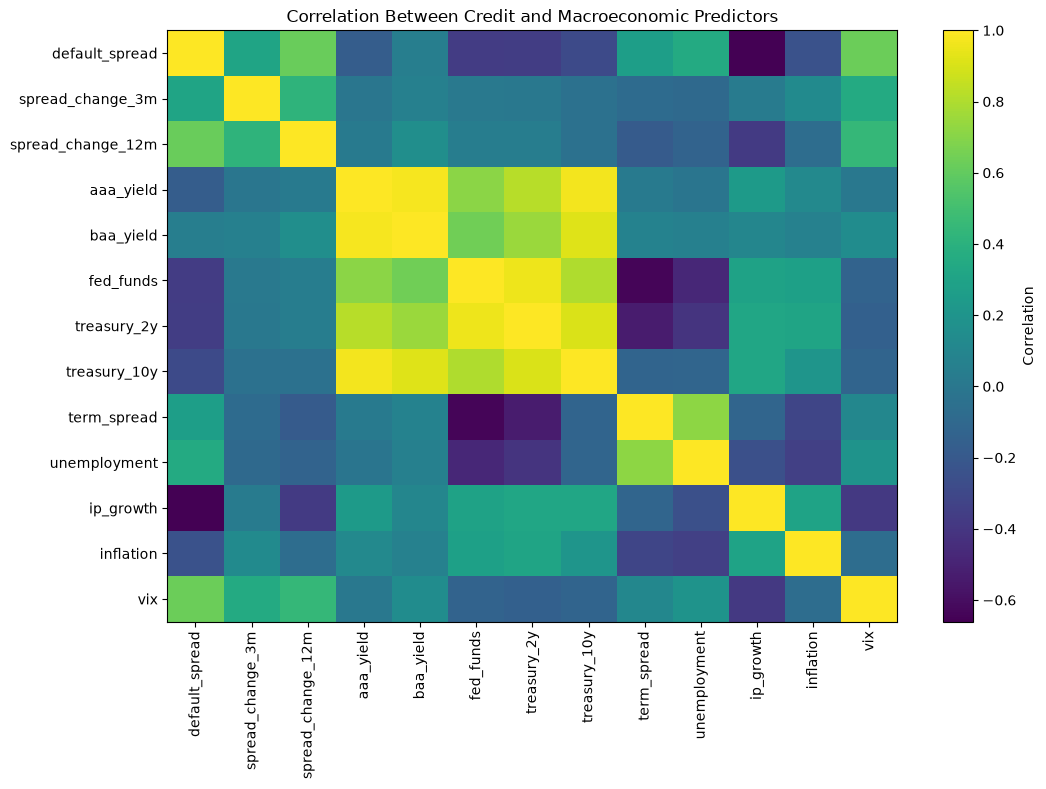

In [158]:
plt.figure(figsize=(11, 8))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(features)),
    features,
    rotation=90
)

plt.yticks(
    range(len(features)),
    features
)

plt.title(
    "Correlation Between Credit and Macroeconomic Predictors"
)

plt.tight_layout()

plt.show()

In [159]:
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(
            correlation_matrix.shape
        ),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper_triangle
    .stack()
    .sort_values(
        key=abs,
        ascending=False
    )
)

correlation_pairs.head(10)

aaa_yield    baa_yield       0.974835
             treasury_10y    0.972245
fed_funds    treasury_2y     0.955693
baa_yield    treasury_10y    0.920069
treasury_2y  treasury_10y    0.904484
aaa_yield    treasury_2y     0.820539
fed_funds    treasury_10y    0.799367
baa_yield    treasury_2y     0.749922
term_spread  unemployment    0.715720
aaa_yield    fed_funds       0.712882
dtype: float64

In [160]:
X = model_df[features]

y = model_df[
    "future_spread_change"
]

In [161]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=False
)

In [162]:
X_train = X_train.iloc[:-6]

y_train = y_train.iloc[:-6]

In [163]:
print(
    "Training observations:",
    len(X_train)
)

print(
    "Test observations:",
    len(X_test)
)

print()

print(
    "Training period:",
    X_train.index.min(),
    "to",
    X_train.index.max()
)

print()

print(
    "Test period:",
    X_test.index.min(),
    "to",
    X_test.index.max()
)

Training observations: 330
Test observations: 84

Training period: 1991-01-01 00:00:00 to 2018-06-01 00:00:00

Test period: 2019-01-01 00:00:00 to 2026-01-01 00:00:00


**Historical-Mean Benchmark**

In [164]:
historical_mean = (
    y_train.mean()
)

historical_mean_pred = np.repeat(
    historical_mean,
    len(y_test)
)

print(
    "Historical mean future spread change:",
    historical_mean
)

Historical mean future spread change: -0.0033030303030303068


In [165]:
scaler = StandardScaler()

X_train_scaled = (
    scaler.fit_transform(
        X_train
    )
)

X_test_scaled = (
    scaler.transform(
        X_test
    )
)

In [166]:
ols = LinearRegression()

ols.fit(
    X_train_scaled,
    y_train
)

ols_pred = ols.predict(
    X_test_scaled
)

ols_coefficients = pd.Series(
    ols.coef_,
    index=features,
    name="OLS"
)

ols_coefficients.round(4)

default_spread      -0.2912
spread_change_3m     0.0369
spread_change_12m    0.0521
aaa_yield           -0.0470
baa_yield           -0.1260
fed_funds            0.0456
treasury_2y         -0.0135
treasury_10y         0.0324
term_spread          0.1007
unemployment        -0.0292
ip_growth           -0.0934
inflation            0.1808
vix                  0.0970
Name: OLS, dtype: float64

In [167]:
ridge_alpha_values = np.logspace(-4,6,140)

regularisation_alpha_values = np.logspace(-4,2,100)

In [168]:
tscv = TimeSeriesSplit(
    n_splits=5,
    gap=6
)

In [169]:
ridge_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "ridge",
        Ridge()
    )
])

ridge_grid = {
    "ridge__alpha":
        ridge_alpha_values
}

In [170]:
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge__alpha': array([1.0000...00000000e+06])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defau

In [171]:
best_ridge_alpha = (
    ridge_search
    .best_params_[
        "ridge__alpha"
    ]
)

print(
    "Best Ridge alpha:",
    best_ridge_alpha
)

Best Ridge alpha: 1000000.0


In [172]:
best_ridge = (
    ridge_search
    .best_estimator_
)

ridge_pred = (
    best_ridge.predict(
        X_test
    )
)

In [173]:
ridge_coefficients = pd.Series(
    best_ridge
    .named_steps["ridge"]
    .coef_,
    index=features,
    name="Ridge"
)

ridge_coefficients.round(4)

default_spread      -0.0001
spread_change_3m     0.0000
spread_change_12m   -0.0000
aaa_yield            0.0000
baa_yield           -0.0000
fed_funds            0.0000
treasury_2y          0.0000
treasury_10y         0.0000
term_spread         -0.0000
unemployment        -0.0000
ip_growth            0.0000
inflation            0.0001
vix                 -0.0000
Name: Ridge, dtype: float64

In [174]:
lasso_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "lasso",
        Lasso(
            max_iter=100000
        )
    )
])

lasso_grid = {
    "lasso__alpha":
        regularisation_alpha_values
}

In [175]:
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso__alpha': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default

In [176]:
best_lasso_alpha = (
    lasso_search
    .best_params_[
        "lasso__alpha"
    ]
)

print(
    "Best LASSO alpha:",
    best_lasso_alpha
)

Best LASSO alpha: 0.21544346900318845


In [177]:
best_lasso = (
    lasso_search
    .best_estimator_
)

lasso_pred = (
    best_lasso.predict(
        X_test
    )
)

In [178]:
lasso_coefficients = pd.Series(
    best_lasso
    .named_steps["lasso"]
    .coef_,
    index=features,
    name="LASSO"
)

lasso_coefficients.round(4)

default_spread       0.0
spread_change_3m     0.0
spread_change_12m    0.0
aaa_yield            0.0
baa_yield            0.0
fed_funds            0.0
treasury_2y          0.0
treasury_10y         0.0
term_spread          0.0
unemployment         0.0
ip_growth            0.0
inflation            0.0
vix                  0.0
Name: LASSO, dtype: float64

**Elastic Net l1_ratio**

In [179]:
l1_ratio_values = [0.05,0.10,0.25,0.50,0.75,0.90,0.95]

In [180]:
elastic_net_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "elastic_net",
        ElasticNet(
            max_iter=100000
        )
    )
])

In [181]:
elastic_net_grid = {
    "elastic_net__alpha":
        regularisation_alpha_values,

    "elastic_net__l1_ratio":
        l1_ratio_values
}

In [182]:
elastic_net_search = GridSearchCV(
    estimator=elastic_net_pipeline,
    param_grid=elastic_net_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

elastic_net_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'elastic_net__alpha': array([1.0000...00000000e+02]), 'elastic_net__l1_ratio': [0.05, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for ca

In [183]:
best_elastic_alpha = (
    elastic_net_search
    .best_params_[
        "elastic_net__alpha"
    ]
)

best_l1_ratio = (
    elastic_net_search
    .best_params_[
        "elastic_net__l1_ratio"
    ]
)

print(
    "Best Elastic Net alpha:",
    best_elastic_alpha
)

print(
    "Best Elastic Net l1_ratio:",
    best_l1_ratio
)

Best Elastic Net alpha: 0.24770763559917114
Best Elastic Net l1_ratio: 0.9


In [184]:
best_elastic_net = (
    elastic_net_search
    .best_estimator_
)

elastic_net_pred = (
    best_elastic_net.predict(
        X_test
    )
)

In [185]:
elastic_net_coefficients = pd.Series(
    best_elastic_net
    .named_steps["elastic_net"]
    .coef_,
    index=features,
    name="Elastic_Net"
)

elastic_net_coefficients.round(4)

default_spread       0.0
spread_change_3m     0.0
spread_change_12m    0.0
aaa_yield            0.0
baa_yield            0.0
fed_funds            0.0
treasury_2y          0.0
treasury_10y         0.0
term_spread          0.0
unemployment         0.0
ip_growth            0.0
inflation            0.0
vix                  0.0
Name: Elastic_Net, dtype: float64

In [186]:
selected_lasso_features = (
    lasso_coefficients[
        lasso_coefficients != 0
    ]
)

selected_elastic_features = (
    elastic_net_coefficients[
        elastic_net_coefficients != 0
    ]
)

print(
    "Total candidate predictors:",
    len(features)
)

print(
    "LASSO predictors selected:",
    len(
        selected_lasso_features
    )
)

print(
    "Elastic Net predictors selected:",
    len(
        selected_elastic_features
    )
)

Total candidate predictors: 13
LASSO predictors selected: 0
Elastic Net predictors selected: 0


In [187]:
selected_elastic_features

elastic_net_coefficients[
    elastic_net_coefficients == 0
]

default_spread       0.0
spread_change_3m     0.0
spread_change_12m    0.0
aaa_yield            0.0
baa_yield            0.0
fed_funds            0.0
treasury_2y          0.0
treasury_10y         0.0
term_spread          0.0
unemployment         0.0
ip_growth            0.0
inflation            0.0
vix                  0.0
Name: Elastic_Net, dtype: float64

In [188]:
coefficient_table = pd.DataFrame({
    "OLS":
        ols_coefficients,

    "Ridge":
        ridge_coefficients,

    "LASSO":
        lasso_coefficients,

    "Elastic_Net":
        elastic_net_coefficients
})

coefficient_table[
    "LASSO_Selected"
] = (
    coefficient_table[
        "LASSO"
    ] != 0
)

coefficient_table[
    "ElasticNet_Selected"
] = (
    coefficient_table[
        "Elastic_Net"
    ] != 0
)

coefficient_table.round(4)

,OLS,Ridge,LASSO,Elastic_Net,LASSO_Selected,ElasticNet_Selected
default_spread,-0.2912,-0.0001,0.0,0.0,False,False
spread_change_3m,0.0369,0.0000,0.0,0.0,False,False
spread_change_12m,0.0521,-0.0000,0.0,0.0,False,False
aaa_yield,-0.0470,0.0000,0.0,0.0,False,False
baa_yield,-0.1260,-0.0000,0.0,0.0,False,False
fed_funds,0.0456,0.0000,0.0,0.0,False,False
treasury_2y,-0.0135,0.0000,0.0,0.0,False,False
treasury_10y,0.0324,0.0000,0.0,0.0,False,False
term_spread,0.1007,-0.0000,0.0,0.0,False,False
unemployment,-0.0292,-0.0000,0.0,0.0,False,False


In [189]:
def evaluate_model(
    y_true,
    y_pred
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return rmse, mae, r2

In [190]:
mean_rmse, mean_mae, mean_r2 = evaluate_model(
    y_test,
    historical_mean_pred
)

ols_rmse, ols_mae, ols_r2 = evaluate_model(
    y_test,
    ols_pred
)

ridge_rmse, ridge_mae, ridge_r2 = evaluate_model(
    y_test,
    ridge_pred
)

lasso_rmse, lasso_mae, lasso_r2 = evaluate_model(
    y_test,
    lasso_pred
)

elastic_rmse, elastic_mae, elastic_r2 = evaluate_model(
    y_test,
    elastic_net_pred
)

In [191]:
performance = pd.DataFrame({
    "Model": [
        "Historical Mean",
        "OLS",
        "Ridge",
        "LASSO",
        "Elastic Net"
    ],

    "RMSE": [
        mean_rmse,
        ols_rmse,
        ridge_rmse,
        lasso_rmse,
        elastic_rmse
    ],

    "MAE": [
        mean_mae,
        ols_mae,
        ridge_mae,
        lasso_mae,
        elastic_mae
    ],

    "R2": [
        mean_r2,
        ols_r2,
        ridge_r2,
        lasso_r2,
        elastic_r2
    ]
})

performance.round(4)

,Model,RMSE,MAE,R2
0,Historical Mean,0.2350,0.1760,-0.0240
1,OLS,0.5283,0.4646,-4.1741
2,Ridge,0.2350,0.1760,-0.0232
3,LASSO,0.2350,0.1760,-0.0240
4,Elastic Net,0.2350,0.1760,-0.0240


In [192]:
def out_of_sample_r2(
    y_true,
    model_pred,
    benchmark_pred
):

    model_error = np.sum(
        (
            y_true.values
            - model_pred
        ) ** 2
    )

    benchmark_error = np.sum(
        (
            y_true.values
            - benchmark_pred
        ) ** 2
    )

    return (
        1
        -
        model_error
        / benchmark_error
    )

In [193]:
ols_oos_r2 = out_of_sample_r2(
    y_test,
    ols_pred,
    historical_mean_pred
)

ridge_oos_r2 = out_of_sample_r2(
    y_test,
    ridge_pred,
    historical_mean_pred
)

lasso_oos_r2 = out_of_sample_r2(
    y_test,
    lasso_pred,
    historical_mean_pred
)

elastic_oos_r2 = out_of_sample_r2(
    y_test,
    elastic_net_pred,
    historical_mean_pred
)

print(
    "OLS OOS R2:",
    round(
        ols_oos_r2,
        4
    )
)

print(
    "Ridge OOS R2:",
    round(
        ridge_oos_r2,
        4
    )
)

print(
    "LASSO OOS R2:",
    round(
        lasso_oos_r2,
        4
    )
)

print(
    "Elastic Net OOS R2:",
    round(
        elastic_oos_r2,
        4
    )
)

OLS OOS R2: -4.0529
Ridge OOS R2: 0.0008
LASSO OOS R2: 0.0
Elastic Net OOS R2: 0.0


**Direction Accuracy**

We want to know whether the model correctly predicts: Spread Widening versus Spread Narrowing

In [194]:
def direction_accuracy(
    y_true,
    y_pred
):

    correct = (
        np.sign(
            y_true.values
        )
        ==
        np.sign(
            y_pred
        )
    )

    return (
        correct.mean()
        * 100
    )

In [195]:
mean_direction = direction_accuracy(
    y_test,
    historical_mean_pred
)

ols_direction = direction_accuracy(
    y_test,
    ols_pred
)

ridge_direction = direction_accuracy(
    y_test,
    ridge_pred
)

lasso_direction = direction_accuracy(
    y_test,
    lasso_pred
)

elastic_direction = direction_accuracy(
    y_test,
    elastic_net_pred
)

print(
    "Historical Mean Direction Accuracy:",
    round(mean_direction, 2),
    "%"
)

print(
    "OLS Direction Accuracy:",
    round(ols_direction, 2),
    "%"
)

print(
    "Ridge Direction Accuracy:",
    round(ridge_direction, 2),
    "%"
)

print(
    "LASSO Direction Accuracy:",
    round(lasso_direction, 2),
    "%"
)

print(
    "Elastic Net Direction Accuracy:",
    round(elastic_direction, 2),
    "%"
)

Historical Mean Direction Accuracy: 67.86 %
OLS Direction Accuracy: 35.71 %
Ridge Direction Accuracy: 67.86 %
LASSO Direction Accuracy: 67.86 %
Elastic Net Direction Accuracy: 67.86 %


**Spread-Widening Recall**

This is a new and useful credit-risk metric.

Suppose actual spread change is positive: y>0.
This means credit conditions actually deteriorated.

Of all months where spreads subsequently widened, how often did the model correctly predict widening?

In [196]:
def widening_recall(
    y_true,
    y_pred
):

    actual_widening = (
        y_true.values > 0
    )

    predicted_widening = (
        y_pred > 0
    )

    correctly_predicted = (
        actual_widening
        &
        predicted_widening
    )

    return (
        correctly_predicted.sum()
        /
        actual_widening.sum()
        * 100
    )

In [197]:
ols_widening = widening_recall(
    y_test,
    ols_pred
)

ridge_widening = widening_recall(
    y_test,
    ridge_pred
)

lasso_widening = widening_recall(
    y_test,
    lasso_pred
)

elastic_widening = widening_recall(
    y_test,
    elastic_net_pred
)

print(
    "OLS Widening Recall:",
    round(
        ols_widening,
        2
    ),
    "%"
)

print(
    "Ridge Widening Recall:",
    round(
        ridge_widening,
        2
    ),
    "%"
)

print(
    "LASSO Widening Recall:",
    round(
        lasso_widening,
        2
    ),
    "%"
)

print(
    "Elastic Net Widening Recall:",
    round(
        elastic_widening,
        2
    ),
    "%"
)

OLS Widening Recall: 100.0 %
Ridge Widening Recall: 0.0 %
LASSO Widening Recall: 0.0 %
Elastic Net Widening Recall: 0.0 %


**Plot: Actual vs Forecast Spread Changes**

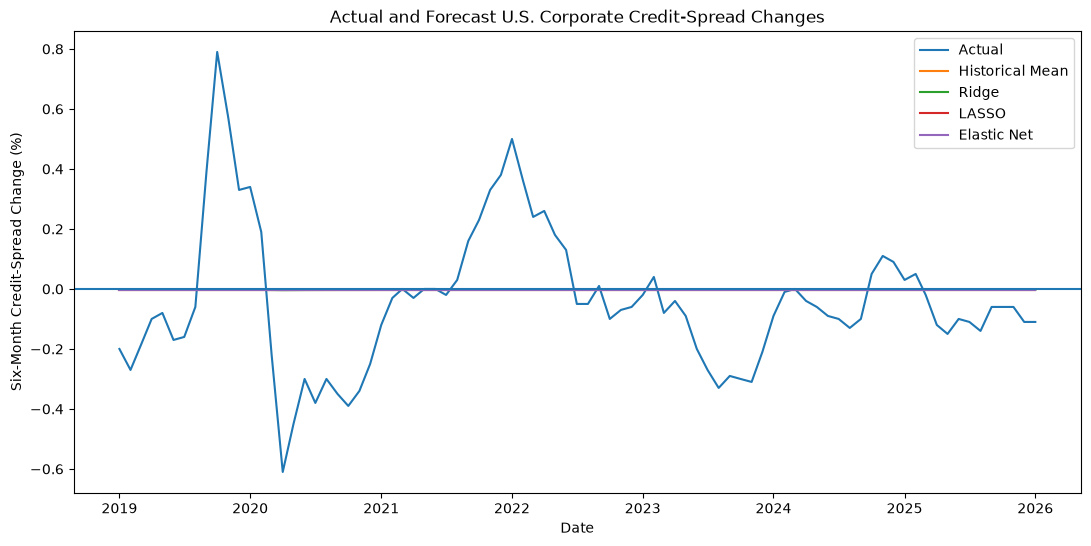

In [198]:
plt.figure(figsize=(13, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual"
)

plt.plot(
    y_test.index,
    historical_mean_pred,
    label="Historical Mean"
)

plt.plot(
    y_test.index,
    ridge_pred,
    label="Ridge"
)

plt.plot(
    y_test.index,
    lasso_pred,
    label="LASSO"
)

plt.plot(
    y_test.index,
    elastic_net_pred,
    label="Elastic Net"
)

plt.axhline(
    y=0
)

plt.xlabel("Date")

plt.ylabel(
    "Six-Month Credit-Spread Change (%)"
)

plt.title(
    "Actual and Forecast U.S. Corporate Credit-Spread Changes"
)

plt.legend()

plt.show()

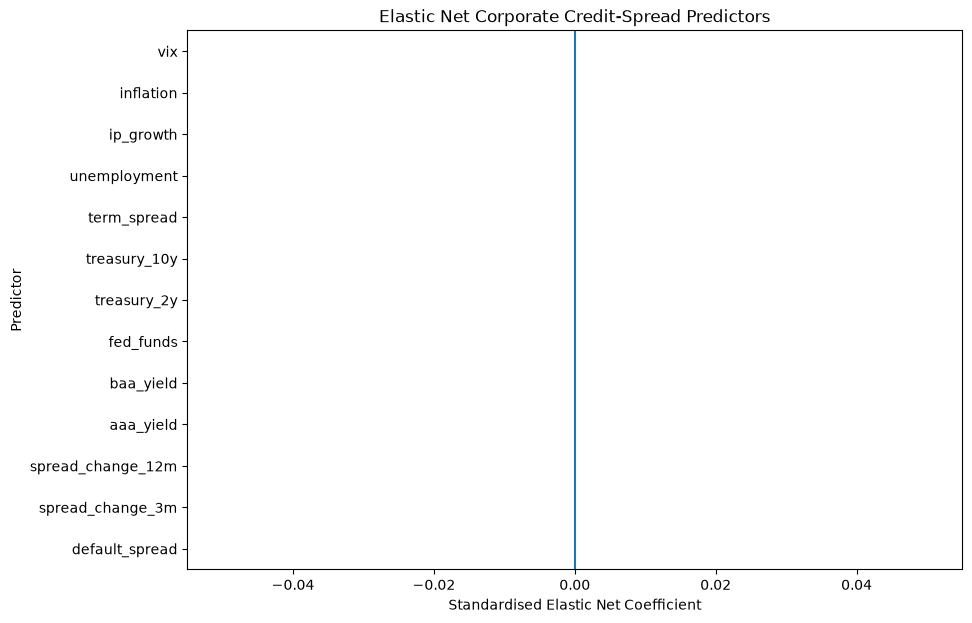

In [199]:
elastic_net_coefficients.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.axvline(
    x=0
)

plt.xlabel(
    "Standardised Elastic Net Coefficient"
)

plt.ylabel(
    "Predictor"
)

plt.title(
    "Elastic Net Corporate Credit-Spread Predictors"
)

plt.show()

**Compare LASSO and Elastic Net**

In [200]:
lasso_elastic_comparison = pd.DataFrame({
    "LASSO":
        lasso_coefficients,

    "Elastic_Net":
        elastic_net_coefficients
})

lasso_elastic_comparison.round(4)

,LASSO,Elastic_Net
default_spread,0.0,0.0
spread_change_3m,0.0,0.0
spread_change_12m,0.0,0.0
aaa_yield,0.0,0.0
baa_yield,0.0,0.0
fed_funds,0.0,0.0
treasury_2y,0.0,0.0
treasury_10y,0.0,0.0
term_spread,0.0,0.0
unemployment,0.0,0.0


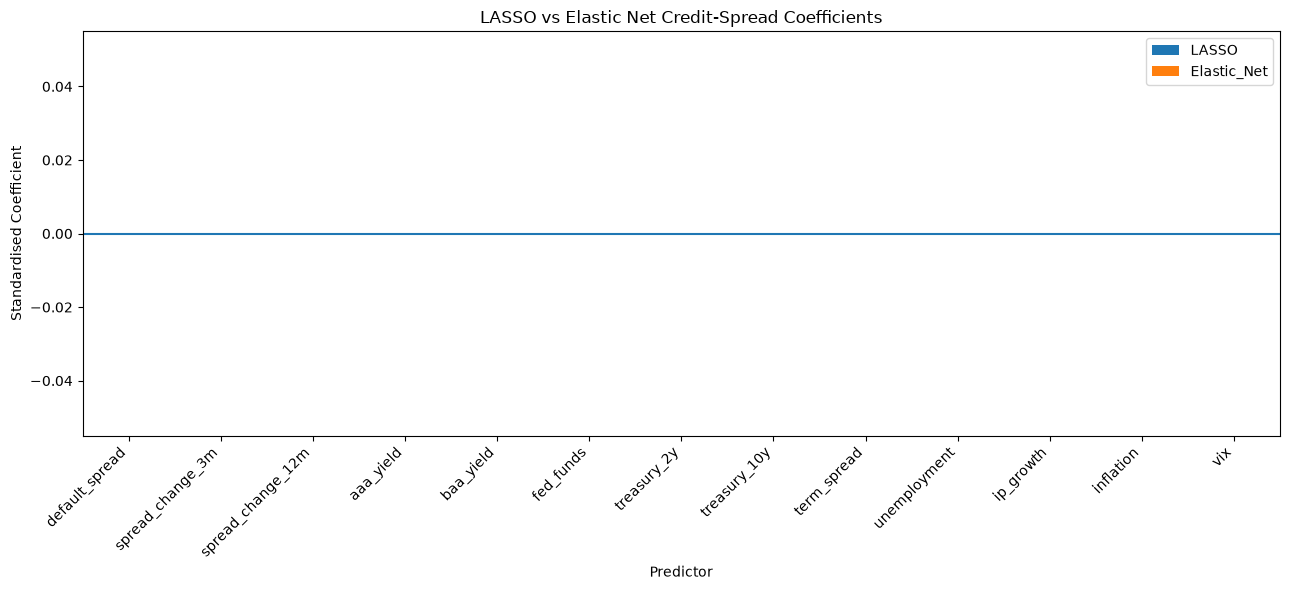

In [201]:
lasso_elastic_comparison.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Predictor"
)

plt.ylabel(
    "Standardised Coefficient"
)

plt.title(
    "LASSO vs Elastic Net Credit-Spread Coefficients"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [202]:
path_scaler = StandardScaler()

X_train_path = (
    path_scaler.fit_transform(
        X_train
    )
)

path_alphas = np.logspace(
    -4,
    2,
    100
)

elastic_coefficient_path = []

for alpha in path_alphas:

    model = ElasticNet(
        alpha=alpha,
        l1_ratio=best_l1_ratio,
        max_iter=100000
    )

    model.fit(
        X_train_path,
        y_train
    )

    elastic_coefficient_path.append(
        model.coef_
    )

elastic_coefficient_path = np.array(
    elastic_coefficient_path
)

**Plot: Coefficient Paths**

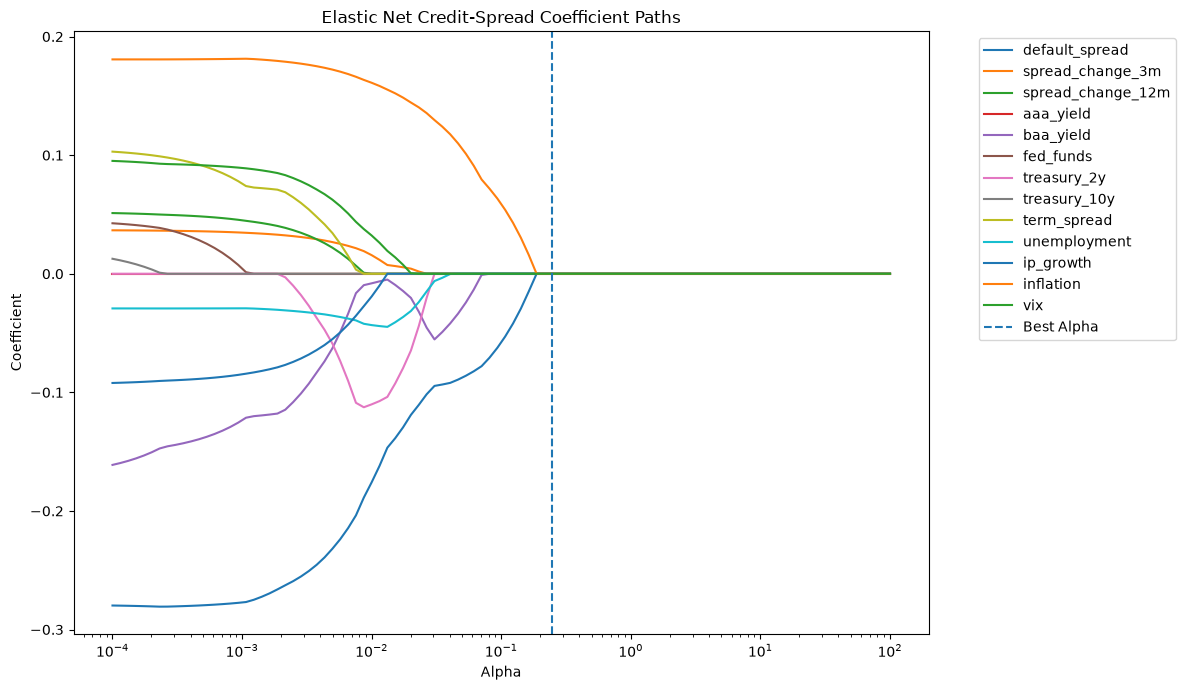

In [203]:
plt.figure(figsize=(12, 7))

for i, feature in enumerate(features):

    plt.semilogx(
        path_alphas,
        elastic_coefficient_path[:, i],
        label=feature
    )

plt.axvline(
    best_elastic_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel("Alpha")

plt.ylabel("Coefficient")

plt.title(
    "Elastic Net Credit-Spread Coefficient Paths"
)

plt.legend(
    bbox_to_anchor=(
        1.05,
        1
    ),
    loc="upper left"
)

plt.tight_layout()

plt.show()

In [204]:
elastic_cv_results = pd.DataFrame(
    elastic_net_search.cv_results_
)

elastic_cv_results[
    "RMSE"
] = (
    -elastic_cv_results[
        "mean_test_score"
    ]
)

elastic_cv_results[
    "alpha"
] = (
    elastic_cv_results[
        "param_elastic_net__alpha"
    ].astype(float)
)

elastic_cv_results[
    "l1_ratio"
] = (
    elastic_cv_results[
        "param_elastic_net__l1_ratio"
    ].astype(float)
)

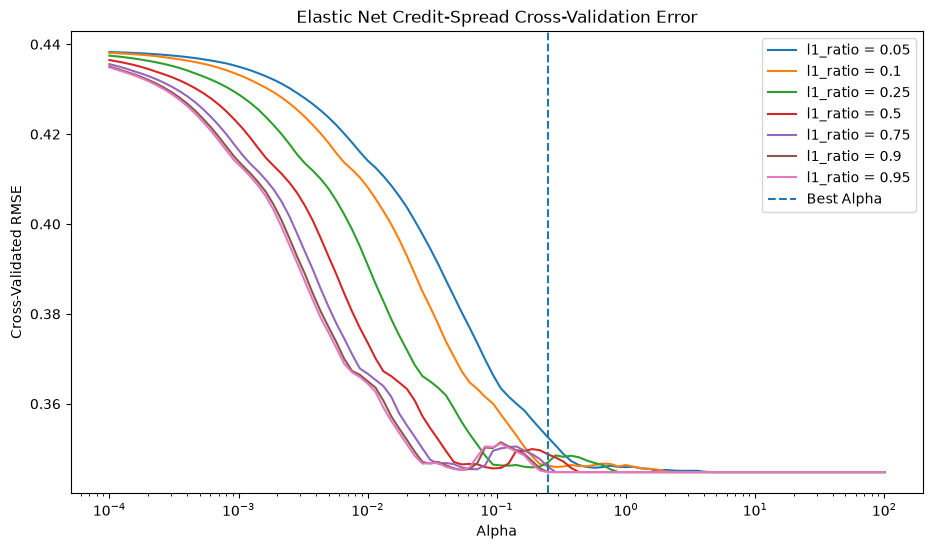

In [205]:
plt.figure(figsize=(11, 6))

for ratio in l1_ratio_values:

    ratio_results = (
        elastic_cv_results[
            elastic_cv_results[
                "l1_ratio"
            ] == ratio
        ]
        .sort_values(
            "alpha"
        )
    )

    plt.semilogx(
        ratio_results["alpha"],
        ratio_results["RMSE"],
        label=f"l1_ratio = {ratio}"
    )

plt.axvline(
    best_elastic_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel("Alpha")

plt.ylabel(
    "Cross-Validated RMSE"
)

plt.title(
    "Elastic Net Credit-Spread Cross-Validation Error"
)

plt.legend()

plt.show()

**Plot: Elastic Net Forecast Residuals**

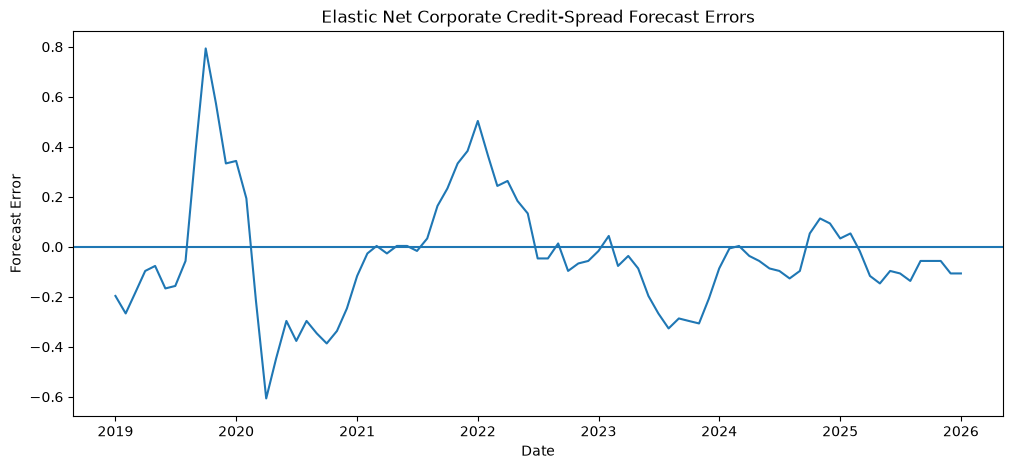

In [206]:
elastic_residuals = (
    y_test.values
    -
    elastic_net_pred
)

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    elastic_residuals
)

plt.axhline(
    y=0
)

plt.xlabel("Date")

plt.ylabel(
    "Forecast Error"
)

plt.title(
    "Elastic Net Corporate Credit-Spread Forecast Errors"
)

plt.show()

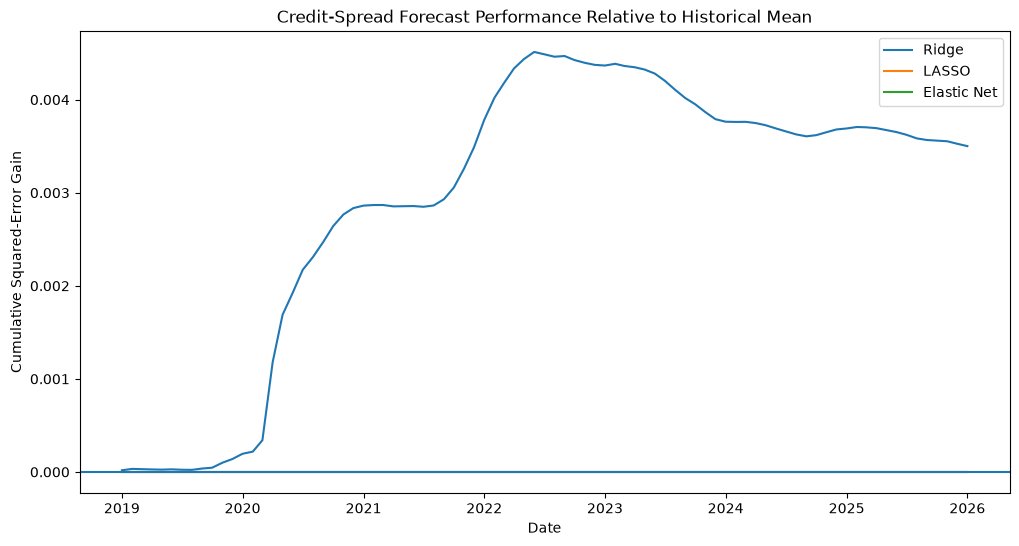

In [207]:
benchmark_squared_error = (
    y_test.values
    -
    historical_mean_pred
) ** 2

ridge_squared_error = (
    y_test.values
    -
    ridge_pred
) ** 2

lasso_squared_error = (
    y_test.values
    -
    lasso_pred
) ** 2

elastic_squared_error = (
    y_test.values
    -
    elastic_net_pred
) ** 2

ridge_cumulative_gain = np.cumsum(
    benchmark_squared_error
    -
    ridge_squared_error
)

lasso_cumulative_gain = np.cumsum(
    benchmark_squared_error
    -
    lasso_squared_error
)

elastic_cumulative_gain = np.cumsum(
    benchmark_squared_error
    -
    elastic_squared_error
)

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    ridge_cumulative_gain,
    label="Ridge"
)

plt.plot(
    y_test.index,
    lasso_cumulative_gain,
    label="LASSO"
)

plt.plot(
    y_test.index,
    elastic_cumulative_gain,
    label="Elastic Net"
)

plt.axhline(
    y=0
)

plt.xlabel("Date")

plt.ylabel(
    "Cumulative Squared-Error Gain"
)

plt.title(
    "Credit-Spread Forecast Performance Relative to Historical Mean"
)

plt.legend()

plt.show()

**Forecast Results Table**

In [208]:
forecast_results = pd.DataFrame({
    "Actual":
        y_test,

    "Historical_Mean":
        historical_mean_pred,

    "OLS":
        ols_pred,

    "Ridge":
        ridge_pred,

    "LASSO":
        lasso_pred,

    "Elastic_Net":
        elastic_net_pred
})

forecast_results.head(10).round(4)

,Actual,Historical_Mean,OLS,Ridge,LASSO,Elastic_Net
DATE,,,,,,
2019-01-01,-0.20,-0.0033,-0.1356,-0.0033,-0.0033,-0.0033
2019-02-01,-0.27,-0.0033,-0.1396,-0.0033,-0.0033,-0.0033
2019-03-01,-0.19,-0.0033,-0.0595,-0.0033,-0.0033,-0.0033
2019-04-01,-0.10,-0.0033,0.0071,-0.0033,-0.0033,-0.0033
2019-05-01,-0.08,-0.0033,0.0335,-0.0033,-0.0033,-0.0033
2019-06-01,-0.17,-0.0033,0.0179,-0.0033,-0.0033,-0.0033
2019-07-01,-0.16,-0.0033,0.0643,-0.0033,-0.0033,-0.0033
2019-08-01,-0.06,-0.0033,0.1953,-0.0033,-0.0033,-0.0033
2019-09-01,0.39,-0.0033,0.1388,-0.0033,-0.0033,-0.0033


In [209]:
forecast_results.tail(10).round(4)

,Actual,Historical_Mean,OLS,Ridge,LASSO,Elastic_Net
DATE,,,,,,
2025-03-01,-0.02,-0.0033,0.3277,-0.0032,-0.0033,-0.0033
2025-04-01,-0.12,-0.0033,0.3953,-0.0033,-0.0033,-0.0033
2025-05-01,-0.15,-0.0033,0.2581,-0.0032,-0.0033,-0.0033
2025-06-01,-0.10,-0.0033,0.3067,-0.0032,-0.0033,-0.0033
2025-07-01,-0.11,-0.0033,0.2655,-0.0032,-0.0033,-0.0033
2025-08-01,-0.14,-0.0033,0.3156,-0.0032,-0.0033,-0.0033
2025-09-01,-0.06,-0.0033,0.3476,-0.0031,-0.0033,-0.0033
2025-11-01,-0.06,-0.0033,0.3626,-0.0032,-0.0033,-0.0033
2025-12-01,-0.11,-0.0033,0.3355,-0.0032,-0.0033,-0.0033


In [210]:
performance.to_csv(
    "problem_15_model_performance.csv",
    index=False
)

coefficient_table.to_csv(
    "problem_15_coefficients.csv"
)

forecast_results.to_csv(
    "problem_15_forecasts.csv"
)

elastic_cv_results.to_csv(
    "problem_15_elastic_net_cv.csv",
    index=False
)

## END